<a href="https://colab.research.google.com/github/dionis-razin/Monte-Carlo-portfolio-risk/blob/main/pairs_trading_stat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q yfinance statsmodels

import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
import matplotlib.pyplot as plt

### Шаг 1. Тест на коинтеграцию (Энгл–Грейнджер)

**Подготовка данных:**
1. Загрузили дневные цены закрытия (`Close`) через `yfinance` с параметром `auto_adjust=True` (с учетом дивидендов и сплитов).
2. Перевели цены в натуральные логарифмы (`np.log`). Это переводит относительные процентные изменения в линейную шкалу и выравнивает масштаб между активами с разной ценой.

**Как работает сам тест (`coint`):**
Тест Энгла–Грейнджера проверяет, существует ли между двумя нестационарными рядами (ценами акций) стационарная линейная комбинация. Он проходит в два этапа:
1. **Регрессия (OLS):** алгоритм подбирает прямую зависимость между $\ln(\text{EWA})$ и $\ln(\text{EWC})$ и вычисляет **остатки** — разницу между фактической ценой и предсказанной (это и есть спред).
2. **Проверка стационарности (тест Дики–Фуллера, ADF):** алгоритм проверяет эти остатки на наличие «единичного корня». Проще говоря: блуждает ли спред случайно куда угодно, или он статистически стремится вернуться к своему среднему значению.

**Интерпретация результата:**
- **Нулевая гипотеза ($H_0$):** коинтеграции нет (спред — случайное блуждание).
- **Полученный `p-value ≈ 0.01`** (ниже порога `0.05`).

Вероятность того, что связь возникла случайно, составляет около 1%. Отклоняем $H_0$ — долгосрочная равновесная связь между `EWA` и `EWC` статистически подтверждена.

In [3]:
tickers = ['EWA', 'EWC']
data = yf.download(tickers, start='2023-11-01', end='2026-11-01', progress=False, auto_adjust=True)['Close'].dropna()

log_ko = np.log(data['EWA'])
log_pep = np.log(data['EWC'])

score, p_value, _ = coint(log_ko, log_pep)
print(f"p-value: {p_value:.4f}")

p-value: 0.0149


### Выбранная пара: EWA и EWC

- **EWA (iShares MSCI Australia ETF)** — отслеживает индекс MSCI Australia.
- **EWC (iShares MSCI Canada ETF)** — отслеживает индекс MSCI Canada.

**Как строятся индексы:**
Оба индекса взвешены по рыночной капитализации с учетом акций в свободном обращении (*free-float market cap*) и покрывают около 85% фондового рынка каждой страны. Крупнейшие компании занимают в них наибольшую долю. В обоих фондах доминируют два сектора:
- **Финансы** (крупные национальные банки).
- **Сырье и энергетика** (в Австралии — горнодобыча: железная руда, литий, золото; в Канаде — нефть, газ и металлы).

**Почему они коррелируют и коинтегрированы:**
1. **Общий макродрайвер — сырьевые циклы.** Обе страны — развитые экспортеры сырья. Рост или спад мировой экономики (и особенно промышленного спроса в Китае и США) одновременно двигает выручку сырьевых компаний обеих стран.
2. **Связь банков с сырьем.** Национальные банки в обоих индексах кредитуют локальную экономику, которая зависит от экспортных доходов, поэтому финансовый сектор двигается в том же цикле.
3. **Похожая монетарная политика.** Центробанки Австралии (RBA) и Канады (BoC) работают в схожих экономических условиях и обычно синхронно реагируют на глобальную инфляцию и ставки ФРС.

В результате оба ETF реагируют на одни и те же фундаментальные факторы, а временные расхождения между ними чаще всего вызваны локальными новостями и со временем сглаживаются.

### Шаг 2. Расчет пропорции (Hedge Ratio) и спреда

После того как тест подтвердил долгосрочную связь между `EWA` и `EWC`, нужно решить две практические задачи: определить точную пропорцию для входа в сделку и измерить текущее расхождение между фондами.

**Как работает расчет:**
Мы строим линейную регрессию (метод наименьших квадратов, OLS) по логарифмам цен:
$$\ln(\text{EWA}) = \alpha + \beta \cdot \ln(\text{EWC}) + \varepsilon$$

По сути, это формула «справедливой цены» `EWA`, рассчитанная на основе цены `EWC`:
- **$\beta$ (`hedge_ratio`)** — коэффициент чувствительности (аналог классической беты, но не ко всему рынку, а конкретно `EWA` к `EWC`). Показывает, на сколько процентов в среднем меняется `EWA`, когда `EWC` двигается на 1%.
- **$\alpha$ (константа)** — техническая поправка на то, что фонды изначально стоят по-разному.
- **$\varepsilon$ (`spread`, остатки `model.resid`)** — ошибка прогноза: разница между реальной ценой `EWA` на бирже и его «справедливой» ценой по формуле. Это и есть спред.

**Что означает результат (`Hedge Ratio = 0.5175`):**
В среднем при движении `EWC` на 1% фонд `EWA` двигается примерно на 0.52% — то есть Канада почти в два раза волатильнее Австралии.

Если вложить в оба фонда одинаковую сумму (1000 USD и 1000 USD), более резкий `EWC` будет перевешивать, и результат сделки будет зависеть от общего направления рынка. Чтобы это убрать, мы уравниваем их по силе: на каждые **1000 USD** в `EWA` открываем противоположную позицию на **517.50 USD** в `EWC`.

*Пример нейтрализации рынка:* если весь сырьевой рынок вырастет (`EWC` на +1%, а `EWA` на +0.5175%), шорт по `EWC` даст убыток **-5.18 USD**, а лонг по `EWA` — прибыль **+5.18 USD**. Общее движение рынка обнуляется, и мы зарабатываем только на том, что фонды возвращаются друг к другу.

**Логика открытия сделок:**
В парном трейдинге одновременно открываются две противоположные позиции: **лонг** (покупка актива в расчете на рост) и **шорт** (продажа взятого взаймы актива в расчете на падение).
- **Спред сильно отрицательный** — реальная цена `EWA` ниже предсказанной (фонд временно недооценен относительно `EWC`). Открываем **лонг `EWA`** и **шорт `EWC`**.
- **Спред сильно положительный** — реальная цена `EWA` выше предсказанной (фонд временно переоценен). Открываем **шорт `EWA`** и **лонг `EWC`**.

In [4]:
log_ewa = np.log(data['EWA'])
log_ewc = np.log(data['EWC'])

X = sm.add_constant(log_ewc)
model = sm.OLS(log_ewa, X).fit()

hedge_ratio = model.params['EWC']
spread = model.resid

print(f"Hedge Ratio (beta): {hedge_ratio:.4f}")

Hedge Ratio (beta): 0.5175


### Шаг 3. Скорость возврата спреда (Half-Life)

Тест на коинтеграцию подтвердил, что `EWA` и `EWC` связаны, а регрессия дала пропорцию для сделки. Но для торговли важно знать не только *вернётся* ли спред к нулю, но и **как быстро** это происходит.

Для этого считают **Half-Life (период полураспада)** — среднее количество торговых дней, за которое расхождение между фондами сокращается ровно вдвое.

**Как работает расчёт:**
Модель описывает спред как растянутую пружину (процесс Орнштейна–Уленбека): чем сильнее спред отклонился вчера, тем сильнее он тянется обратно сегодня.

1. **Ищем дневную скорость возврата ($\theta$):**
   Строим линейную регрессию (OLS) между вчерашним отклонением спреда ($S_{t-1}$) и его сегодняшним изменением ($\Delta S_t = S_t - S_{t-1}$):
   $$\Delta S_t = c + \theta \cdot S_{t-1} + \varepsilon_t$$
   Коэффициент **$\theta$** показывает, какую долю вчерашнего отклонения рынок в среднем отыгрывает за один день. Например, $\theta = -0.10$ означает, что каждый день разрыв в среднем сжимается на 10%. Знак «минус» обязателен — он подтверждает, что спред именно *возвращается* к нулю, а не улетает дальше.

2. **Переводим скорость в торговые дни:**
   Поскольку каждый день спред сжимается от *оставшейся* величины (как сложный процент наоборот), его затухание описывается экспонентой $S(t) = S_0 \cdot e^{\theta t}$. Чтобы найти время $t$, за которое отклонение уменьшится вдвое ($S(t) = 0.5 \cdot S_0$), решаем уравнение через натуральный логарифм:
   $$t = -\frac{\ln(2)}{\theta}$$
   Здесь $\ln(2) \approx 0.693$ — константа, переводящая дневной процент возврата в точное число дней.

**Зачем это на практике:**
- **Слишком большой Half-Life (например, 80–100+ дней):** капитал надолго замораживается в сделке, плата за удержание шорта съедает прибыль, а за несколько месяцев фундаментальная связь между активами может вообще сломаться.
- **Оптимальный Half-Life (обычно от нескольких дней до 3–4 недель):** позволяет совершать достаточное количество сделок в год с понятным горизонтом удержания.

In [5]:
spread_lag = spread.shift(1).dropna()
spread_diff = spread.diff().dropna()

ou_model = sm.OLS(spread_diff, sm.add_constant(spread_lag)).fit()
theta = ou_model.params.iloc[1]

half_life = -np.log(2) / theta
print(f"Half-Life: {half_life:.1f} дней")

Half-Life: 17.4 дней


### Шаг 4. Превращаем спред в торговый сигнал (Z-Score)

Сам по себе спред — это сырые числа (например, `0.03` или `-0.04`). Глядя на них, невозможно сразу понять, является ли текущее расхождение аномальным или это обычный дневной шум.

Чтобы получить универсальную шкалу для входа в сделку, спред стандартизируют с помощью **Z-Score** — показателя, который измеряет, на сколько стандартных отклонений (сигм) текущий спред ушёл от своего среднего значения:

$$Z_t = \frac{\text{Spread}_t - \mu_t}{\sigma_t}$$

**Как работает расчёт:**
- **Скользящее окно (`window = 20`):** среднее ($\mu_t$) и стандартное отклонение ($\sigma_t$) считаются не за всю историю сразу, а за последние 20 торговых дней (примерно один месяц). Это решает две задачи: алгоритм не «подглядывает» в будущее и автоматически подстраивается под текущую волатильность рынка.
- **Масштаб:** `Z-Score` всегда колеблется вокруг `0` (текущее среднее). Чем дальше значение от нуля, тем сильнее «натянута пружина».

**Логика торговых сигналов:**
По статистике, выход за пределы двух стандартных отклонений (`+2` и `-2`) происходит редко, поэтому эти уровни используют как точки входа:
- **`Z-Score < -2` (зелёная линия):** спред экстремально низкий, `EWA` сильно недооценён относительно `EWC` — сигнал открывать **лонг `EWA`** и **шорт `EWC`**.
- **`Z-Score > +2` (красная линия):** спред экстремально высокий, `EWA` сильно переоценён — сигнал открывать **шорт `EWA`** и **лонг `EWC`**.

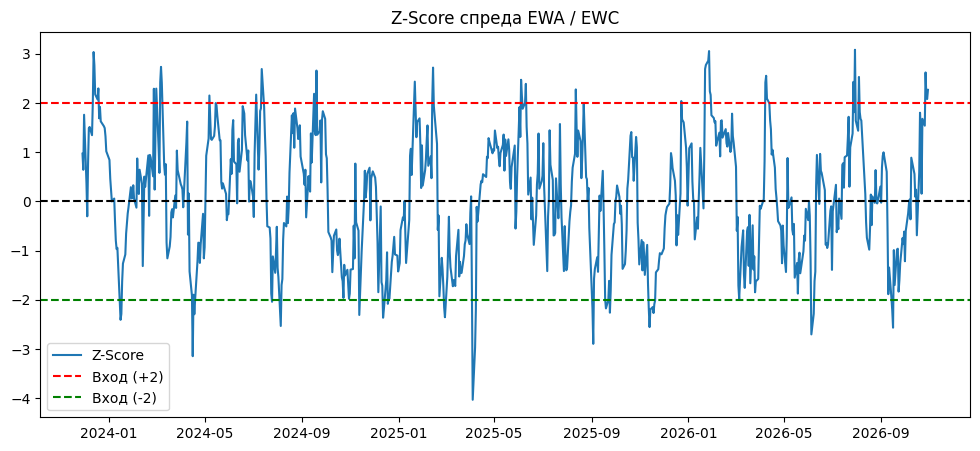

In [6]:
import matplotlib.pyplot as plt

window = 20
rolling_mean = spread.rolling(window=window).mean()
rolling_std = spread.rolling(window=window).std()

z_score = (spread - rolling_mean) / rolling_std

plt.figure(figsize=(12, 5))
plt.plot(z_score, label='Z-Score')
plt.axhline(0, color='black', linestyle='--')
plt.axhline(2, color='red', linestyle='--', label='Вход (+2)')
plt.axhline(-2, color='green', linestyle='--', label='Вход (-2)')
plt.legend()
plt.title('Z-Score спреда EWA / EWC')
plt.show()

### Шаг 5. Торговые сигналы и первый бэктест (Backtesting)

Когда правила входа и выхода определены, стратегию проверяют на исторических данных. Он показывает, как менялся бы капитал, если бы мы торговали по этому алгоритму в прошлом.

**Как работает расчёт:**

1. **Формируем позиции (`positions`):**
   - `1` — открываем **лонг `EWA`** и **шорт `EWC`**, когда `Z-Score < -2`.
   - `-1` — открываем **шорт `EWA`** и **лонг `EWC`**, когда `Z-Score > +2`.
   - `0` — закрываем сделку и фиксируем результат, когда `Z-Score` возвращается в нейтральную зону вокруг нуля (от `-0.5` до `+0.5`).
   - Метод `ffill()` (forward fill) протягивает открытую позицию (`1` или `-1`) на все следующие дни, пока не придёт сигнал на выход.

2. **Считаем дневную доходность (`strategy_ret`):**
   - Через `pct_change()` получаем дневное процентное изменение каждого фонда.
   - Объединяем их с учётом пропорции из Шага 2: `ret_ewa - hedge_ratio * ret_ewc`.
   - Умножаем на сдвинутую позицию `positions.shift(1)`. Сдвиг на 1 день — обязательная защита от «подглядывания в будущее»: сигнал появляется по цене закрытия сегодняшнего дня, поэтому реальную прибыль или убыток от сделки мы начинаем получать только завтра.

3. **Строим кривую капитала (`cum_ret`):**
   - Формула `(1 + strategy_ret).cumprod()` последовательно перемножает дневные доходности (эффект сложного процента). График стартует с `1.0` и показывает, во сколько раз вырос или уменьшился бы вложенный капитал за весь период.

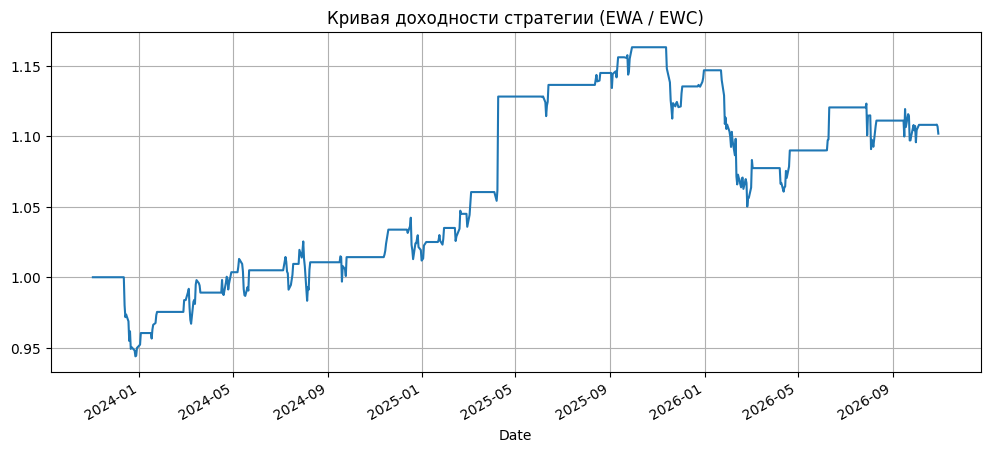

In [7]:
positions = pd.Series(index=z_score.index, dtype=float)
positions[z_score < -2] = 1
positions[z_score > 2] = -1
positions[(z_score > -0.5) & (z_score < 0.5)] = 0

positions = positions.ffill().fillna(0)

ret_ewa = data['EWA'].pct_change()
ret_ewc = data['EWC'].pct_change()
strategy_ret = positions.shift(1) * (ret_ewa - hedge_ratio * ret_ewc)

cum_ret = (1 + strategy_ret).cumprod()
cum_ret.plot(figsize=(12, 5), title='Кривая доходности стратегии (EWA / EWC)')
plt.grid(True)
plt.show()

### Итоги и выводы по проекту (Pairs Trading: EWA / EWC)

В ходе проекта мы построили и протестировали базовую стратегию статистического арбитража на паре сырьевых ETF — Австралии (`EWA`) и Канады (`EWC`).

**Ключевые результаты:**
- **Коинтеграция:** тест Энгла–Грейнджера показал `p-value = 0.01` (ниже порога 0.05), что статистически подтвердило наличие долгосрочной связи между фондами.
- **Пропорция (Hedge Ratio):** линейная регрессия дала `beta = 0.5175`. Поскольку `EWC` почти вдвое волатильнее `EWA`, для нейтрализации общего движения рынка на каждые 1000 USD в `EWA` требуется открывать противоположную позицию на 517.50 USD в `EWC`.
- **Скорость возврата (Half-Life):** период полураспада спреда составил **17.4 торговых дня** (около 3.5 недель) — это комфортный рабочий диапазон (в идеале от 5 до 30 дней).
- **Бэктест:** на исторических данных стратегия показала итоговый рост капитала около **+10%** почти за три года (с пиком до +16.5% в конце 2025 года и ощутимыми просадками в начале 2024 и 2026 годов).

**Главный практический вывод:**
Несмотря на то что пара идеально прошла все статистические проверки, в текущем виде стратегия **не подходит для реальной торговли**:
1. **Запас доходности слишком мал:** ~3% годовых на практике полностью «съедятся» биржевыми комиссиями (4 транзакции на каждый полный цикл сделки), проскальзыванием и ежедневной платой брокеру за удержание шорта (Borrow Fee).
2. **Связь может временно ломаться:** просадки на графике показывают, что спред способен долго растягиваться против открытой позиции. В реальных алгоритмах для защиты от этого обязательно добавляют стоп-лосс (например, принудительное закрытие при `|Z-Score| > 3.5`) и динамически пересчитывают `Hedge Ratio` в скользящем окне.